# EDA: цены газа и карбамида (World Bank Pink Sheet)

Перед запуском выполни из корня репозитория `python src/data/load_pink_sheet.py` — он создаст `data/processed/prices_monthly.parquet`.

Период анализа — с апреля 2015 года: с этого месяца газ Европы в Pink Sheet считается по TTF.

In [1]:
import numpy as np                                   # математика
import pandas as pd                                  # таблицы
import matplotlib.pyplot as plt                      # графики

df = pd.read_parquet("../data/processed/prices_monthly.parquet")   # ноутбук лежит в notebooks/, поэтому ../

K = 26                       # расход газа на тонну карбамида, млн БТЕ/т (предварительно, уточняет Владислав)
START = "2015-04"            # с апреля 2015 газ Европы = TTF

df["gas_cost"] = K * df["gas_europe"]                     # газовая себестоимость, $/т
df["markup"] = df["urea_price"] - df["gas_cost"]          # надбавка, $/т
df["r_urea"] = np.log(df["urea_price"]).diff()            # лог-приращение цены карбамида (≈ % за месяц)
df["r_gas"] = np.log(df["gas_europe"]).diff()             # лог-приращение цены газа
df["d_markup"] = df["markup"].diff()                      # изменение надбавки за месяц, $/т

s = df.loc[START:]                                        # рабочий период
print(len(s), "месяцев:", s.index.min().date(), "—", s.index.max().date())
s[["urea_price", "gas_europe", "markup"]].describe().round(1)

138 месяцев: 2015-04-01 — 2026-09-01


,urea_price,gas_europe,markup
count,138.0,138.0,138.0
mean,351.7,11.8,44.5
std,174.0,11.1,187.9
min,142.6,1.6,-1229.7
25%,233.8,5.2,36.6
50%,286.2,8.0,83.8
75%,394.5,13.2,117.5
max,925.0,70.0,456.2


## 1. Газ в трёх регионах
Рынки газа разделены: в Европе газ бывает в разы дороже, чем в США.

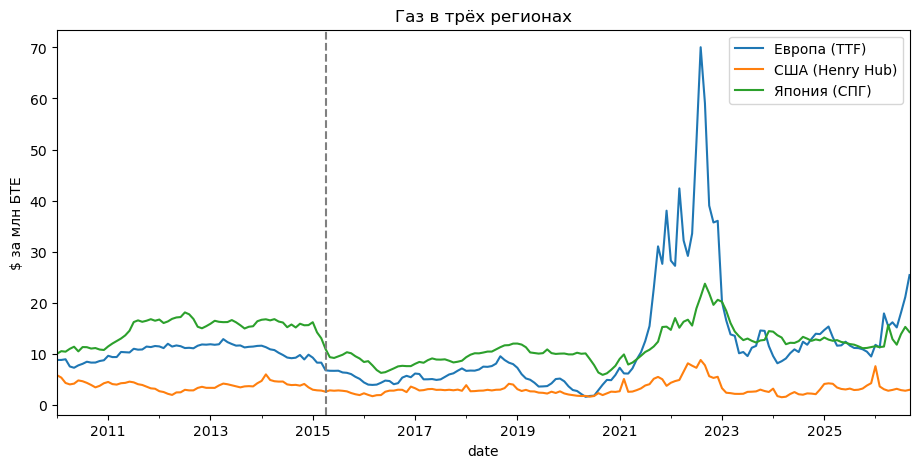

In [2]:
ax = df.loc["2010":, ["gas_europe", "gas_us", "lng_japan"]].plot(figsize=(11, 5))
ax.axvline(pd.Timestamp("2015-04-01"), color="grey", linestyle="--")      # с этого месяца газ Европы = TTF
ax.set_ylabel("$ за млн БТЕ")
ax.legend(["Европа (TTF)", "США (Henry Hub)", "Япония (СПГ)"])
ax.set_title("Газ в трёх регионах")
plt.show()

## 2. Цена карбамида и газовая себестоимость
Обе линии в $/т на одной оси. Промежуток между ними — надбавка.

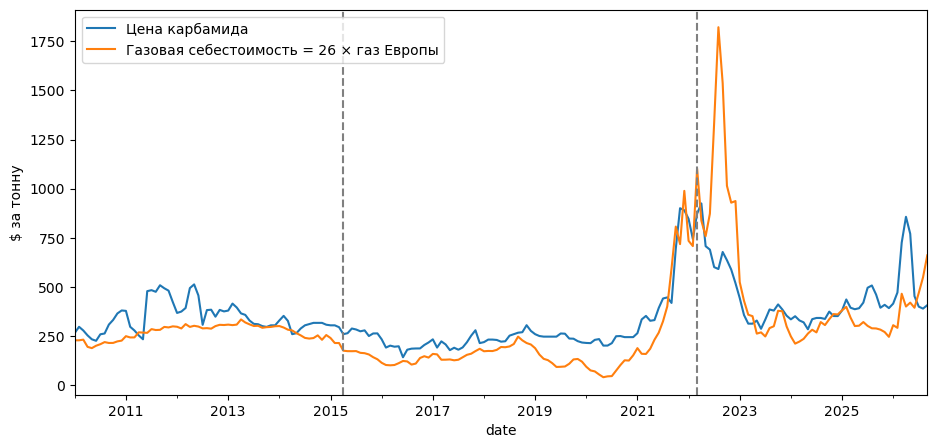

In [3]:
ax = df.loc["2010":, ["urea_price", "gas_cost"]].plot(figsize=(11, 5))
ax.axvline(pd.Timestamp("2015-04-01"), color="grey", linestyle="--")      # газ = TTF
ax.axvline(pd.Timestamp("2022-03-01"), color="grey", linestyle="--")      # карбамид: Чёрное море -> Ближний Восток
ax.set_ylabel("$ за тонну")
ax.legend(["Цена карбамида", f"Газовая себестоимость = {K} × газ Европы"])
plt.show()

## 3. Надбавка: среднее и разброс за 12 месяцев
Стационарный ряд держит среднее и разброс примерно на одном уровне.

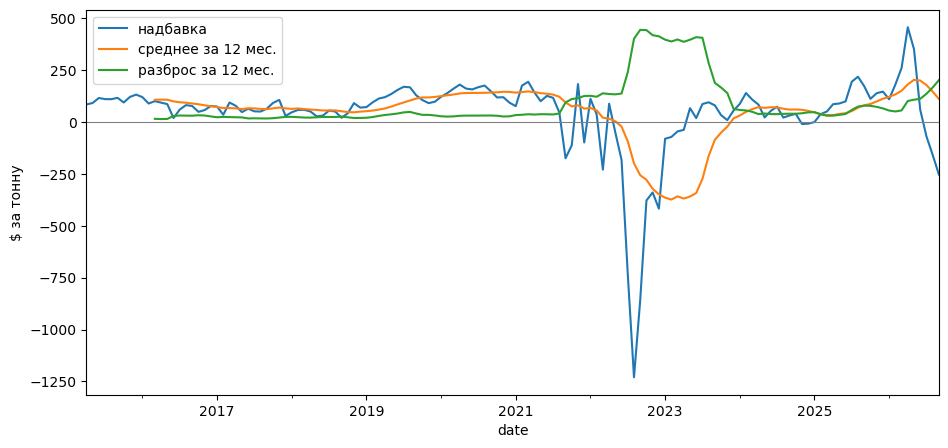

In [4]:
ax = s["markup"].plot(figsize=(11, 5), label="надбавка")
s["markup"].rolling(12).mean().plot(ax=ax, label="среднее за 12 мес.")     # скользящее среднее
s["markup"].rolling(12).std().plot(ax=ax, label="разброс за 12 мес.")      # скользящее стандартное отклонение
ax.axhline(0, color="grey", linewidth=0.8)                                 # ниже нуля — цена ниже себестоимости
ax.set_ylabel("$ за тонну")
ax.legend()
plt.show()

## 4. Сезонность
STL раскладывает ряд на тренд, сезонность и остаток. Ниже — медианное изменение цены по месяцам.

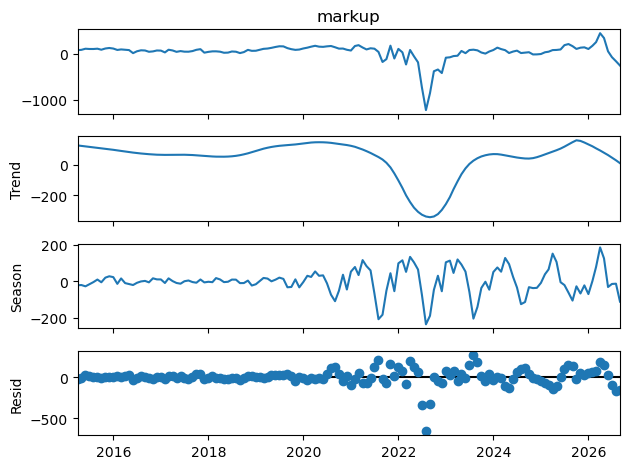

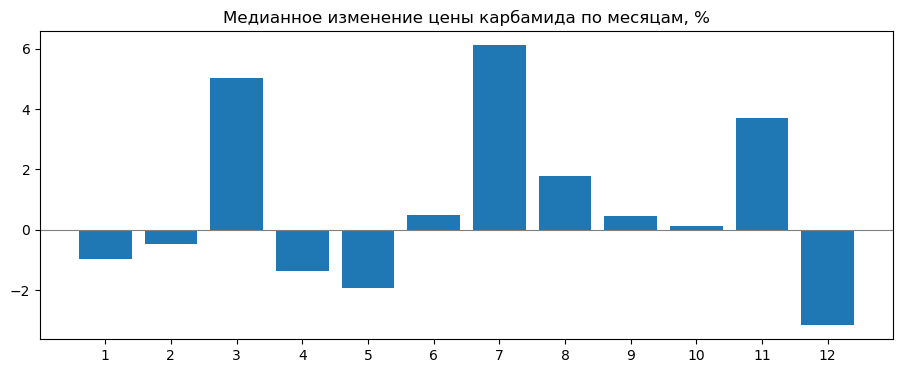

In [5]:
from statsmodels.tsa.seasonal import STL

STL(s["markup"], period=12).fit().plot()               # period=12 — годовая сезонность на месячных данных
plt.show()

by_month = s["r_urea"].groupby(s.index.month).median() * 100   # медианное изменение цены по месяцам, %
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(by_month.index, by_month.values)                 # столбик на каждый месяц
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(range(1, 13))
ax.set_title("Медианное изменение цены карбамида по месяцам, %")
plt.show()

## 5. Автокорреляция надбавки (ACF, PACF)
Столбики за голубой полосой — значимые. Быстрое затухание = надбавка возвращается к среднему.

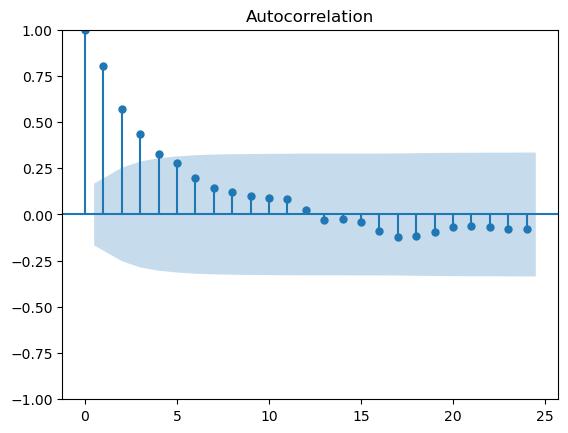

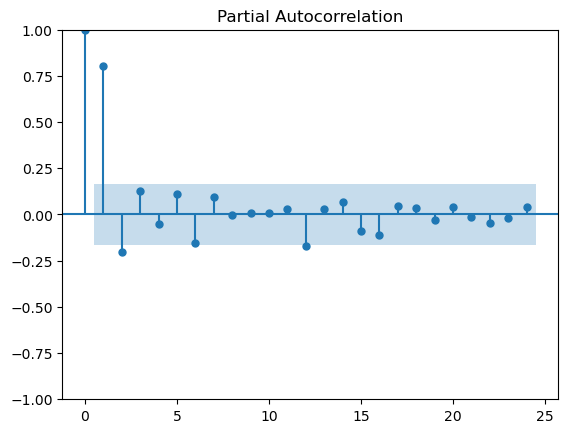

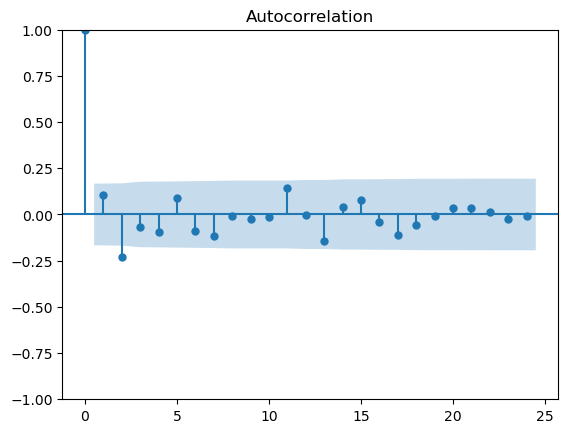

In [6]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(s["markup"], lags=24)                         # корреляция надбавки с собой k месяцев назад
plot_pacf(s["markup"], lags=24)                        # то же без влияния промежуточных лагов
plot_acf(s["d_markup"].dropna(), lags=24)              # для изменений надбавки
plt.show()

## 6. С каким отставанием газ влияет на карбамид
Корреляция изменения цены карбамида в месяц t с изменением газа в месяц t − k. Граница случайности ≈ ±2/√n.

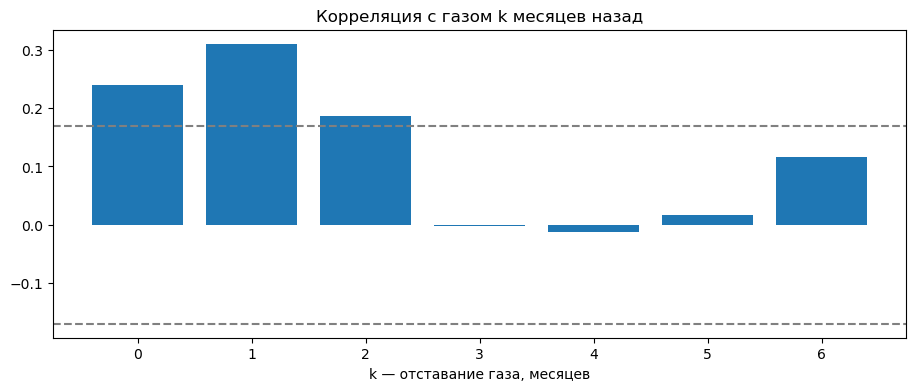

0    0.241
1    0.311
2    0.187
3   -0.002
4   -0.012
5    0.017
6    0.117
dtype: float64

In [7]:
lags = range(0, 7)
ccf = pd.Series([s["r_urea"].corr(s["r_gas"].shift(k)) for k in lags], index=list(lags))   # газ сдвинут на k месяцев назад
band = 2 / np.sqrt(s["r_urea"].notna().sum())                                       # граница случайности

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(ccf.index, ccf.values)                            # столбик на каждое отставание k
ax.set_xlabel("k — отставание газа, месяцев")
ax.set_title("Корреляция с газом k месяцев назад")
ax.axhline(band, color="grey", linestyle="--")
ax.axhline(-band, color="grey", linestyle="--")
plt.show()
ccf.round(3)

## 7. Тесты стационарности: ADF и KPSS
- ADF: нулевая гипотеза — ряд **нестационарен**. p < 0,05 → стационарен.
- KPSS: нулевая гипотеза — ряд **стационарен**. p < 0,05 → нестационарен.

Если оба теста согласны, вывод надёжный.

In [8]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")                       # KPSS предупреждает, когда p-value за пределами таблицы

rows = []
for col in ["urea_price", "markup", "r_urea", "d_markup"]:
    x = s[col].dropna()
    adf_t, adf_p, *_ = adfuller(x, autolag="AIC")       # AIC сам выбирает число лагов
    kpss_stat, kpss_p, *_ = kpss(x, regression="c", nlags="auto")
    rows.append({"ряд": col, "ADF t": round(adf_t, 2), "ADF p": round(adf_p, 3), "KPSS p": round(kpss_p, 3)})

# устойчивость: надбавка без кризиса 2021–2022
x = s["markup"][(s.index < "2021-01-01") | (s.index > "2022-12-01")]
adf_t, adf_p, *_ = adfuller(x, autolag="AIC")
rows.append({"ряд": "markup без 2021–2022", "ADF t": round(adf_t, 2), "ADF p": round(adf_p, 3), "KPSS p": None})

pd.DataFrame(rows)

,ряд,ADF t,ADF p,KPSS p
0,urea_price,-2.38,0.148,0.01
1,markup,-3.42,0.010,0.10
2,r_urea,-2.88,0.048,0.10
3,d_markup,-5.73,0.000,0.10
4,markup без 2021–2022,-3.85,0.002,NaN


## 8. Полураспад надбавки
За сколько месяцев отклонение надбавки от среднего сокращается вдвое: ln(0,5) / ln(φ), где φ — автокорреляция на лаге 1.

In [9]:
phi = s["markup"].autocorr(lag=1)
print("phi =", round(phi, 2), "| полураспад, мес. =", round(np.log(0.5) / np.log(phi), 1))

phi = 0.81 | полураспад, мес. = 3.3


## 9. Тест Грейнджера
Помогает ли прошлое газа предсказать карбамид сверх прошлого самого карбамида. p < 0,05 → помогает.

In [10]:
from statsmodels.tsa.stattools import grangercausalitytests

def granger_p(target, cause, maxlag=6):
    data = s[[target, cause]].dropna()                   # первая колонка — что предсказываем, вторая — чем
    res = grangercausalitytests(data, maxlag=maxlag, verbose=False)
    return {lag: round(res[lag][0]["ssr_ftest"][1], 3) for lag in range(1, maxlag + 1)}

print("газ -> карбамид:", granger_p("r_urea", "r_gas"))
print("карбамид -> газ:", granger_p("r_gas", "r_urea"))   # обратная проверка: должна быть незначима

газ -> карбамид: {1: 0.001, 2: 0.001, 3: 0.001, 4: 0.005, 5: 0.011, 6: 0.002}
карбамид -> газ: {1: 0.537, 2: 0.291, 3: 0.357, 4: 0.344, 5: 0.311, 6: 0.278}
